We learned about the real numbers in school. The real numbers form an infinite field. As in we know that there are infinite numbers from negative numbers to 0 to positive numbers and all those numbers follow some set of properties like addition, subtraction, multiplication, division etc.

<span id="finite-fields" data-learnt="2026-11-03" data-topic="Finite Fields in cryptography"></span>Similar to this infinite numbers, Finite fields is another set of numbers (or actually elements because it can be anything, it does not need to be a number) that have some mathematical set of properties, which can be used to build cryptographic building blocks.

#### Shamir’s secret sharing

##### One point, many lines

<span id="one-point" data-learnt="2026-11-03" data-topic="One point, many lines"></span>Suppose you know only one point in a graph. Many straight lines pass through this point. Each line shown crosses the y-axis at a different value.

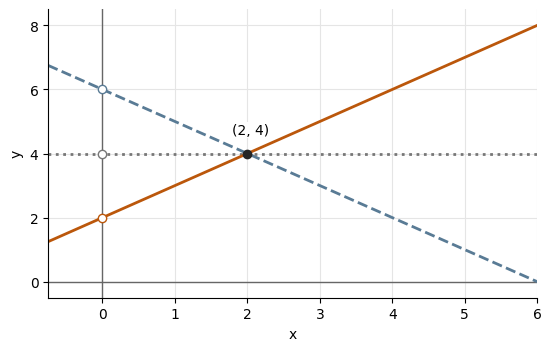

In [1]:
#| echo: false
#| classes: [line-plot]
#| fig-alt: "Three lines pass through (2, 4). They cross the y-axis at 6, 4, and 2."
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

def graph(y_limits):
    fig, ax = plt.subplots(figsize=(5.4, 3.4), layout="constrained")
    ax.set(xlim=(-0.75, 6), ylim=y_limits, xlabel="x", ylabel="y")
    ax.set_xticks(range(7))
    ax.yaxis.set_major_locator(MultipleLocator(2))
    ax.set_axisbelow(True)
    ax.grid(color="#e5e5e5")
    ax.axvline(0, color="#666666", linewidth=1)
    if y_limits[0] < 0:
        ax.axhline(0, color="#666666", linewidth=1)
    ax.spines[["right", "top"]].set_visible(False)
    return ax

def mark(ax, x, y, offset=(6, 7)):
    ax.scatter(x, y, color="#252525", zorder=4)
    ax.annotate(f"({x}, {y})", (x, y), xytext=offset, textcoords="offset points",
                bbox=dict(facecolor="white", edgecolor="none", pad=1))

ax = graph((-0.5, 8.5))
x_values = [-0.75, 6]
for slope, color, style in [(-1, "#597b95", "--"), (0, "#777777", ":"), (1, "#bb570b", "-")]:
    y_values = [4 + slope * (x - 2) for x in x_values]
    ax.plot(x_values, y_values, color=color, linestyle=style, linewidth=2)
    ax.scatter(0, 4 - 2 * slope, facecolor="white", edgecolor=color, zorder=3)
mark(ax, 2, 4, (-11, 14))
plt.show()

##### Two points, one line

<span id="two-points" data-learnt="2026-11-03" data-topic="Two points, one line"></span>However if you know of two points in a graph, then there is only one straight line passing through both those points, and it intersects the y-axis at one value.

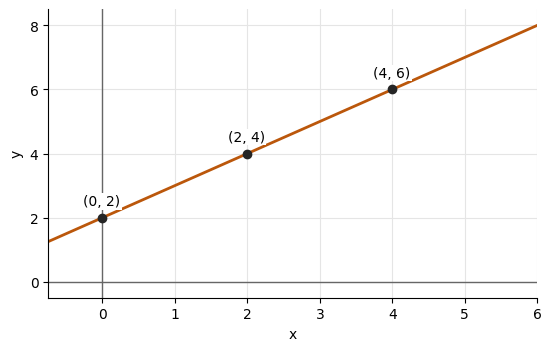

In [2]:
#| echo: false
#| classes: [line-plot]
#| fig-alt: "The line through (2, 4) and (4, 6) crosses the y-axis at (0, 2)."
ax = graph((-0.5, 8.5))
ax.plot(x_values, [2 + x for x in x_values], color="#bb570b", linewidth=2)
for x, y in [(0, 2), (2, 4), (4, 6)]:
    mark(ax, x, y, (-14, 9))
plt.show()

<span id="sharing-nine" data-learnt="2026-11-03" data-topic="Shamir’s secret sharing"></span>This property can be used to share a secret value with someone. Suppose you want to share the secret number 9 with someone. Since you chose 9 as the secret, the line must cross the y-axis at (0, 9). Choose its slope at random.

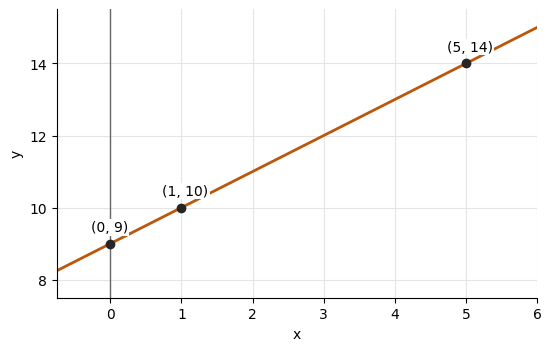

In [3]:
#| echo: false
#| classes: [line-plot]
#| fig-alt: "The line y = 9 + x passes through (0, 9), (1, 10), and (5, 14)."
ax = graph((7.5, 15.5))
ax.plot(x_values, [9 + x for x in x_values], color="#bb570b", linewidth=2)
for x, y in [(0, 9), (1, 10), (5, 14)]:
    mark(ax, x, y, (-14, 9))
plt.show()

The line rises 1 unit for each unit you move to the right.

So, its formula is f(x) = 9 + x, which only you know.

Now, you share two points on this line with two of your friends.

The first friend is shown that f(1) = 10, and second friend is shown that f(5) = 14

So, now if each of your friends only know their share of the secret, that is they both only know their one point on the line, then it is impossible to guess the value of the secret. This is because for one point, there are an infinite number of straight lines that can pass through that point, and the y-axis. This is known as perfect secrecy.

But if both the friends combine their points, then there is only one straight line that goes through the two points, and intersects the y-axis. By doing this, they can know the secret number.

Next, let’s look at a few limitations.

#### Computers dont like real numbers


In [2]:
def f(x):
    return 1 + 4/3 * x

friend_1 = f(3)
friend_2 = f(4)

print(f"friend_1: {friend_1}")
print(f"friend_2: {friend_2}")

friend_1: 5.0
friend_2: 6.333333333333333


The second friends exact value is 19/3. Python prints 6.333333333333333, which is very close. This rounding can change the recovered secret slightly. Computers normally store numbers as bytes. But writing out every digit of 6.333333333333333 would take infinite space.

For the same example above, if we removed fractions, and replaced it with whole integer values, it would be accurate.

In [6]:
def f(x):
    return 1 + 4 * x

friend_1 = f(3)
friend_2 = f(4)

print(f"friend_1: {friend_1}")
print(f"friend_2: {friend_2}")

friend_1: 13
friend_2: 17


Now, we only get results which are whole integer values, which can be stored as bytes. And, by combining the above two results, it is possible to get the secret.

But this introduces a new problem. Let's look at what friend_1 knows.

friend_1 knows that input 3 gives output 13.
friend_1 does not know the equation. Doesn't know the slope or the secret (where the line crosses the y-axis).
So, there are infinite options to choose from.

But, friend_1 knows that the slope must be an integer. No fractions allowed.
So, friend_1 can try guessing:

- Could the secret be 1? Yes. Because with a secret of 1, and choosing a slope of 4, we get the result 13. That is `1 + 4 * 3 = 13`
- Could the secret be 2? No. Because with a secret of 2, we need a slope of 11/3, to get the result 13. That is `2 + (11/3) * 3 = 13`. But we don't allow fractions.
- Could the secret be 3? No. Because with a secret of 3, we need a slope of 10/3, to get the result 13. That is `3 + (10/3) * 3 = 13`. But we don't allow fractions.
- Could the secret be 4? Yes. Because with a secret of 4, and choosing a slope of 3, we get the result 13. That is `4 + 3 * 3 = 13`

So, from one point, the friend cannot determine the secret. But they can rule out some values, so perfect secrecy is lost.